# Fig. 5 — Optimal treatment strategy across evolutionary game space
β and γ are swept over $[-1, 1]$ with α = 0.4, δ = 0.6. At each point the dose maximizing
$J = \tfrac12(R_N/100 + S_L)$ at $T = 15$ days is found for every single intervention (A) and every pair (B), and the best one is shown.
Single agents: dose grid of 21 values; pairs: 11 × 11 dose grid. Runtime: a few minutes.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from lf_model import *
set_style()
from itertools import combinations
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

In [2]:
n_grid = 51
bv = np.linspace(-1, 1, n_grid)
B, G = np.meshgrid(bv, bv)                     # [gamma, beta]
T, dt = 15.0, 0.05
_, N_untr = simulate(ALPHA, B, G, DELTA, T=T, dt=dt)

def best_J(dose_dict):
    x_t, n_t = simulate(*perturbed(B, G, dose_dict), T=T, dt=dt)
    J = 0.5 * ((N_untr - n_t) / N_untr + (1 - x_t))
    return J.max(axis=tuple(range(J.ndim - 2))) if J.ndim > 2 else J

d1 = np.linspace(0, 1, 21)[:, None, None]
single = np.stack([best_J({tg: d1}) for tg in TARGETS])            # [target, gamma, beta]

d2 = np.linspace(0, 1, 11)
pairs = list(combinations(TARGETS, 2))
pair_J = np.stack([best_J({p: d2[:, None, None, None], q: d2[None, :, None, None]}) for p, q in pairs])
best_single, best_pair = single.argmax(0), pair_J.argmax(0)
for k, tg in enumerate(TARGETS):
    print(f"{tg:5s} best single agent on {100 * np.mean(best_single == k):.1f}% of the plane")
for k, (p, q) in enumerate(pairs):
    print(f"{p}+{q}: best pair on {100 * np.mean(best_pair == k):.1f}% of the plane")

alpha best single agent on 23.8% of the plane
beta  best single agent on 17.7% of the plane
gamma best single agent on 7.2% of the plane
delta best single agent on 51.2% of the plane
alpha+beta: best pair on 9.2% of the plane
alpha+gamma: best pair on 5.3% of the plane
alpha+delta: best pair on 44.4% of the plane
beta+gamma: best pair on 8.1% of the plane
beta+delta: best pair on 24.8% of the plane
gamma+delta: best pair on 8.1% of the plane


Saved ../figures/Fig5_optimal_treatment_game_space.png/.pdf


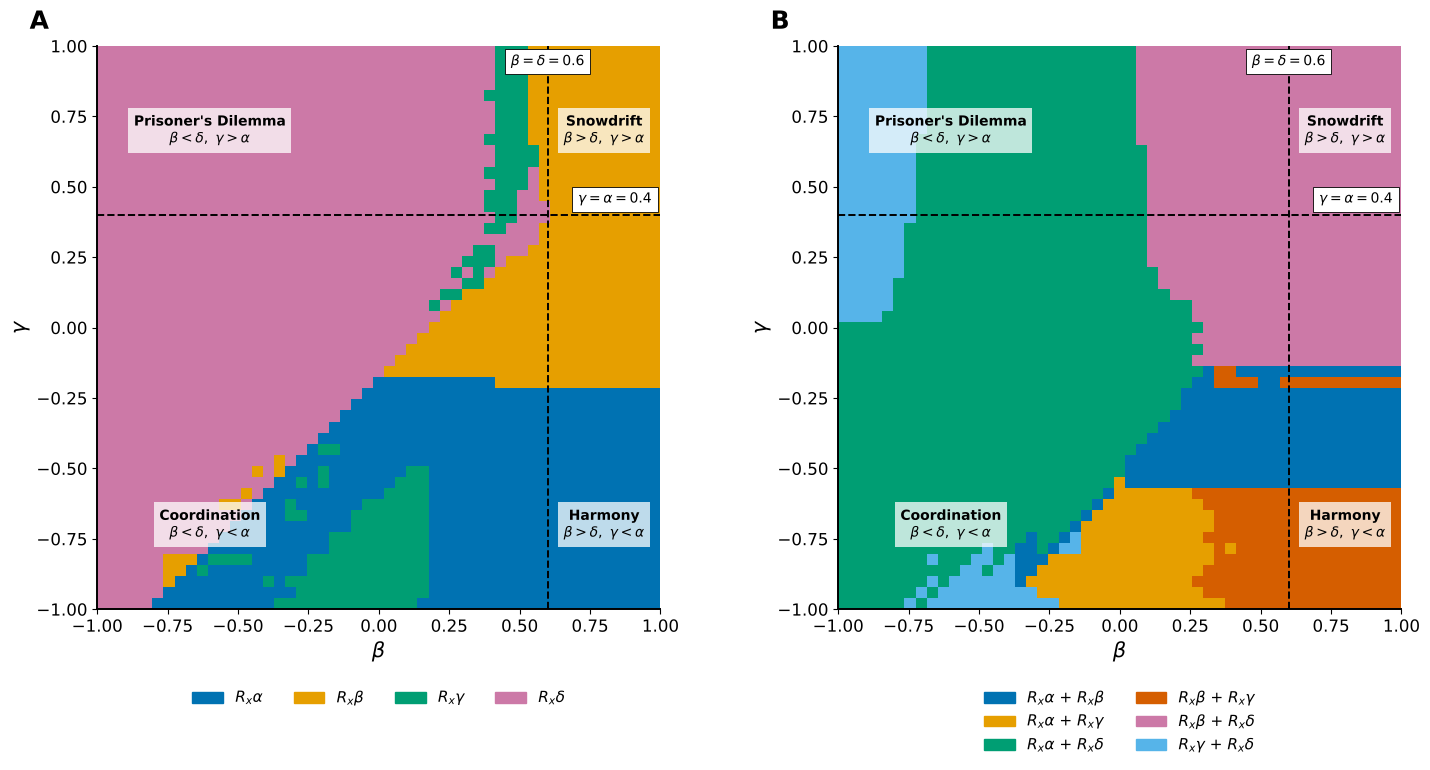

In [3]:
single_cols = ["#0072B2", "#E69F00", "#009E73", "#CC79A7"]
pair_cols = ["#0072B2", "#E69F00", "#009E73", "#D55E00", "#CC79A7", "#56B4E9"]
fig, axes = plt.subplots(1, 2, figsize=(15, 7.4))
for ax, data, cols, labels, letter in [
        (axes[0], best_single, single_cols, [TARGET_LABEL[t] for t in TARGETS], "A"),
        (axes[1], best_pair, pair_cols, [f"{TARGET_LABEL[p]} + {TARGET_LABEL[q]}" for p, q in pairs], "B")]:
    ax.imshow(data, origin="lower", extent=[-1, 1, -1, 1], cmap=ListedColormap(cols),
              vmin=-0.5, vmax=len(cols) - 0.5, interpolation="nearest", aspect="equal")
    ax.axvline(DELTA, color="k", ls="--", lw=1.4); ax.axhline(ALPHA, color="k", ls="--", lw=1.4)
    ax.text(DELTA, 0.97, r"$\beta=\delta=0.6$", ha="center", va="top", fontsize=10,
            bbox=dict(fc="white", ec="k", lw=0.6))
    ax.text(0.97, ALPHA + 0.03, r"$\gamma=\alpha=0.4$", ha="right", va="bottom", fontsize=10,
            bbox=dict(fc="white", ec="k", lw=0.6))
    for xx, yy, txt in [(-0.6, 0.7, "Prisoner's Dilemma\n" r"$\beta<\delta,\ \gamma>\alpha$"),
                        (0.8, 0.7, "Snowdrift\n" r"$\beta>\delta,\ \gamma>\alpha$"),
                        (-0.6, -0.7, "Coordination\n" r"$\beta<\delta,\ \gamma<\alpha$"),
                        (0.8, -0.7, "Harmony\n" r"$\beta>\delta,\ \gamma<\alpha$")]:
        ax.text(xx, yy, txt, ha="center", va="center", fontsize=10, fontweight="bold",
                bbox=dict(fc="white", ec="none", alpha=0.75))
    ax.set_xlabel(r"$\beta$"); ax.set_ylabel(r"$\gamma$")
    ax.legend(handles=[Patch(color=c, label=l) for c, l in zip(cols, labels)], loc="upper center",
              bbox_to_anchor=(0.5, -0.12), ncol=2 if len(cols) > 4 else 4, frameon=False)
    panel_letter(ax, letter, x=-0.12, y=1.02)
fig.tight_layout()
save(fig, "Fig5_optimal_treatment_game_space")
plt.show()